In [344]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error
import joblib

In [345]:
dataset = pd.read_csv("/content/drive/MyDrive/IDS_Lab_8_datasets/HomeValue_Prices.csv")

In [346]:
dataset.shape

(6000, 10)

In [347]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Bedrooms                     5991 non-null   float64
 1   Bathrooms                    6000 non-null   int64  
 2   Area_sqft                    6000 non-null   int64  
 3   Location                     5995 non-null   object 
 4   House_Age                    6000 non-null   int64  
 5   Distance_from_CityCenter_km  5999 non-null   float64
 6   Parking                      6000 non-null   object 
 7   Garden                       5999 non-null   object 
 8   Solar                        5999 non-null   object 
 9   Selling_Price                5998 non-null   float64
dtypes: float64(3), int64(3), object(4)
memory usage: 468.9+ KB


In [348]:
dataset.head()

,Bedrooms,Bathrooms,Area_sqft,Location,House_Age,Distance_from_CityCenter_km,Parking,Garden,Solar,Selling_Price
0,4.0,2,4335,Johar Town,29,22.81,No,Yes,Yes,34235250.0
1,5.0,5,3665,Wapda Town,36,12.55,No,Yes,No,29724194.0
2,3.0,4,3859,DHA,0,13.04,Yes,Yes,No,35439541.0
3,5.0,4,1506,Model Town,24,10.71,Yes,Yes,No,13069088.0
4,5.0,5,4708,Bahria Town,20,19.84,Yes,Yes,No,41647711.0


In [349]:
dataset.isnull().sum()

,0
Bedrooms,9
Bathrooms,0
Area_sqft,0
Location,5
House_Age,0
Distance_from_CityCenter_km,1
Parking,0
Garden,1
Solar,1
Selling_Price,2


In [350]:
dataset.duplicated().sum()

np.int64(4)

In [351]:
dataset['Bedrooms'] = abs(dataset['Bedrooms'])
dataset['Bedrooms'] = dataset['Bedrooms'].fillna(np.ceil(dataset['Bedrooms'].mean()))

dataset["Bathrooms"] = abs(dataset["Bathrooms"])

dataset["Area_sqft"] = abs(dataset["Area_sqft"])

dataset["Location"] = dataset["Location"].fillna(dataset["Location"].mode()[0])

dataset["House_Age"] = abs(dataset["House_Age"])
dataset["House_Age"] = dataset["House_Age"].fillna(dataset["House_Age"].mean())

dataset["Distance_from_CityCenter_km"] = abs(dataset["Distance_from_CityCenter_km"])
dataset["Distance_from_CityCenter_km"] = dataset["Distance_from_CityCenter_km"].fillna(dataset["Distance_from_CityCenter_km"].mean())

dataset["Selling_Price"] = abs(dataset["Selling_Price"])
dataset["Selling_Price"] = dataset["Selling_Price"].fillna(dataset["Selling_Price"].mean())

dataset["Garden"] = dataset["Garden"].fillna(dataset["Garden"].mode()[0])
dataset["Solar"] = dataset["Solar"].fillna(dataset["Solar"].mode()[0])

In [352]:
dataset.isnull().sum()

,0
Bedrooms,0
Bathrooms,0
Area_sqft,0
Location,0
House_Age,0
Distance_from_CityCenter_km,0
Parking,0
Garden,0
Solar,0
Selling_Price,0


In [353]:
dataset = dataset.drop_duplicates()

In [354]:
dataset.duplicated().sum()

np.int64(0)

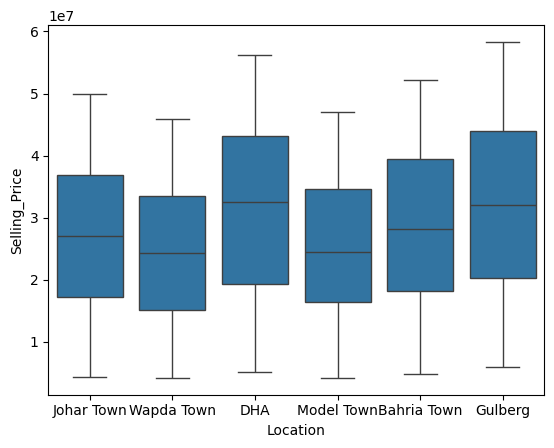

In [355]:
sns.boxplot(x=dataset["Location"], y = dataset['Selling_Price'])
plt.show()

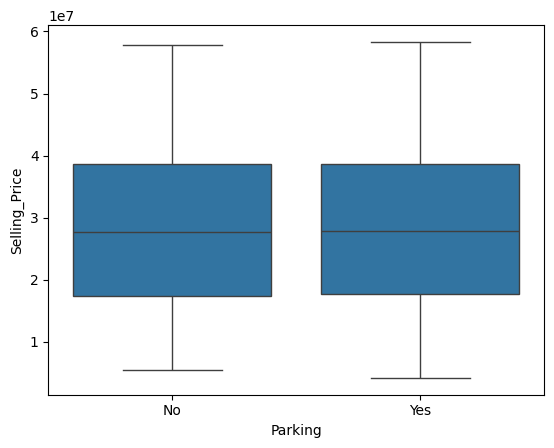

In [356]:
sns.boxplot(x=dataset["Parking"], y = dataset['Selling_Price'])
plt.show()

In [357]:
print(dataset["Location"].unique())
print(dataset["Garden"].unique())
print(dataset["Solar"].unique())
print(dataset["Parking"].unique())

['Johar Town' 'Wapda Town' 'DHA' 'Model Town' 'Bahria Town' 'Gulberg']
['Yes' 'No']
['Yes' 'No']
['No' 'Yes']


In [358]:
label_encoder = LabelEncoder()
dataset["Location"] = label_encoder.fit_transform(dataset["Location"])
dataset["Garden"] = label_encoder.fit_transform(dataset["Garden"])
dataset["Solar"] = label_encoder.fit_transform(dataset["Solar"])
dataset["Parking"] = label_encoder.fit_transform(dataset["Parking"])

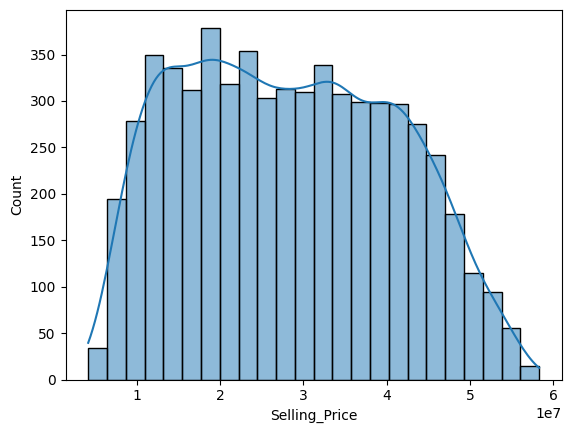

In [359]:
sns.histplot(y, kde=True)
plt.show()

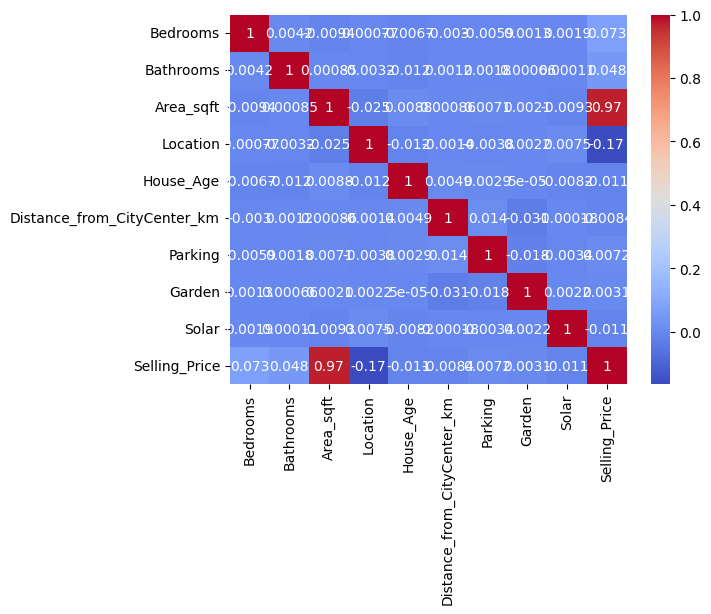

In [360]:
sns.heatmap(dataset.corr(), annot = True, cmap="coolwarm")
plt.show()

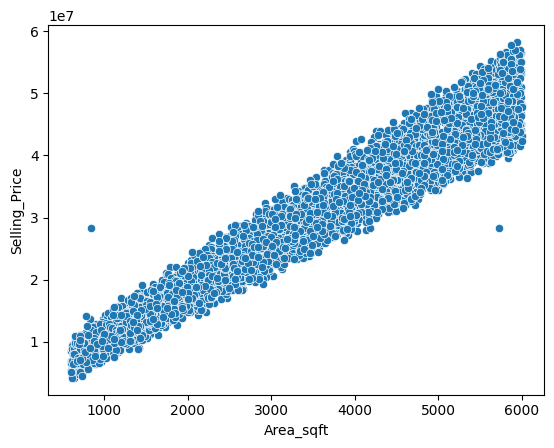

In [361]:
sns.scatterplot(x = dataset["Area_sqft"], y = dataset['Selling_Price'])
plt.show()

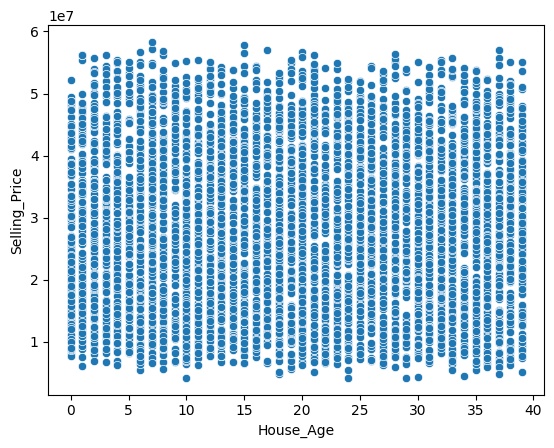

In [362]:
sns.scatterplot(x = dataset["House_Age"], y = dataset['Selling_Price'])
plt.show()

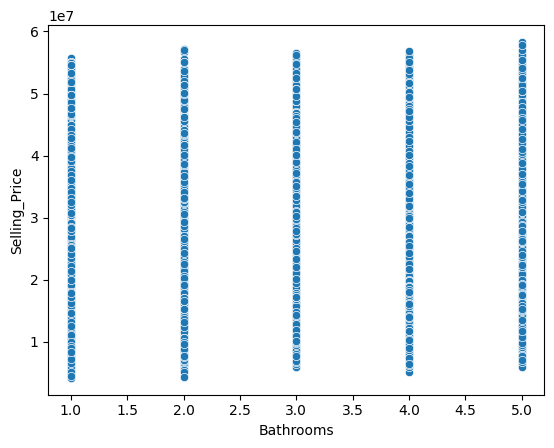

In [363]:
sns.scatterplot(x = dataset["Bathrooms"], y = dataset['Selling_Price'])
plt.show()

In [364]:
scaler = StandardScaler()
dataset[["Bedrooms", "Bathrooms", "Area_sqft", "House_Age", "Distance_from_CityCenter_km"]] = scaler.fit_transform(dataset[["Bedrooms", "Bathrooms", "Area_sqft", "House_Age", "Distance_from_CityCenter_km"]])

In [365]:
y = dataset["Selling_Price"]
x = dataset.drop("Selling_Price", axis=1)

In [366]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state = 42)

In [367]:
regression = LinearRegression()
model = regression.fit(x_train, y_train)

In [368]:
results = model.predict(x_test)

In [369]:
mean_absolute_error(y_test, results)

1711590.9800449037

In [370]:
mean_squared_error(y_test, results)

4704550181212.06

In [371]:
r2_score(y_test, results)

0.970901021430099

In [372]:
root_mean_squared_error(y_test, results)

2168997.506040996

In [377]:
print("Please enter the following details to predict the house price:")

user_input = {
    "Bedrooms": int(input("Number of bedrooms: ")),
    "Bathrooms": int(input("Number of bathrooms: ")),
    "Area_sqft": float(input("Area in square feet: ")),
    "Location": input("Location: "),
    "House_Age": int(input("House age in years: ")),
    "Distance_from_CityCenter_km": float(input("Distance from city center (in km): ")),
    "Parking": input("Parking available? (Yes/No): "),
    "Garden": input("Garden available? (Yes/No): "),
    "Solar": input("Solar panels installed? (Yes/No): ")
}

data = pd.DataFrame([user_input])

Please enter the following details to predict the house price:
Number of bedrooms: 4
Number of bathrooms: 4
Area in square feet: 3000
Location: Gulberg
House age in years: 5
Distance from city center (in km): 10
Parking available? (Yes/No): Yes
Garden available? (Yes/No): Yes
Solar panels installed? (Yes/No): Yes


In [378]:
data["Location"] = label_encoder.fit_transform(data["Location"])
data["Garden"] = label_encoder.fit_transform(data["Garden"])
data["Solar"] = label_encoder.fit_transform(data["Solar"])
data["Parking"] = label_encoder.fit_transform(data["Parking"])

In [379]:
data[["Bedrooms", "Bathrooms", "Area_sqft", "House_Age", "Distance_from_CityCenter_km"]] = scaler.transform(data[["Bedrooms", "Bathrooms", "Area_sqft", "House_Age", "Distance_from_CityCenter_km"]])

In [384]:
print((model.predict(data))[0])

29719768.199714113


In [385]:
joblib.dump(model, "house_price_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(label_encoder, "encoder.pkl")


['encoder.pkl']